In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

# Зареждане — входът е файлът с ВЕЧЕ попълнен volume от предходната тетрадка
df = pd.read_csv(
    "data/traffic_imputed.csv",
    parse_dates=["datetime"]
)

# Feature Engineering — идентични календарни признаци като при volume
df["hour"]          = df["datetime"].dt.hour
df["dow"]           = df["datetime"].dt.dayofweek
df["month"]         = df["datetime"].dt.month
df["direction_enc"] = (df["direction"] == "Център").astype(int)
df["hour_sin"]      = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]      = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"]       = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"]       = np.cos(2 * np.pi * df["dow"] / 7)
df["month_sin"]     = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"]     = np.cos(2 * np.pi * df["month"] / 12)

# Флаг дали volume в този час е реален или вече импутиран (RF/GAN от предходната стъпка)
df["volume_is_imputed"] = df["imputation_method"].notna().astype(int)

# ВАЖНО: тук volume влиза като допълнителен предиктор (Вариант А) —
# физически обосновано през връзката flow-density-speed.
feature_cols = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
                "month_sin", "month_cos", "direction_enc",
                "volume", "volume_is_imputed"]

print(f"Редове           : {len(df):,}")
print(f"Null avg_speed   : {df['avg_speed'].isnull().sum():,} ({df['avg_speed'].isnull().mean()*100:.1f}%)")
print(f"Период           : {df['datetime'].min()} → {df['datetime'].max()}")
print(f"От тях с volume, който е бил импутиран: {df.loc[df['avg_speed'].isnull(), 'volume_is_imputed'].sum():,}")

Устройство: cuda
Редове           : 52,608
Null avg_speed   : 17,977 (34.2%)
Период           : 2022-01-01 00:00:00 → 2024-12-31 23:00:00
От тях с volume, който е бил импутиран: 16,625


ВИЗУАЛИЗАЦИЯ НА ОРИГИНАЛНИЯ ВРЕМЕВИ РЕД (avg_speed)


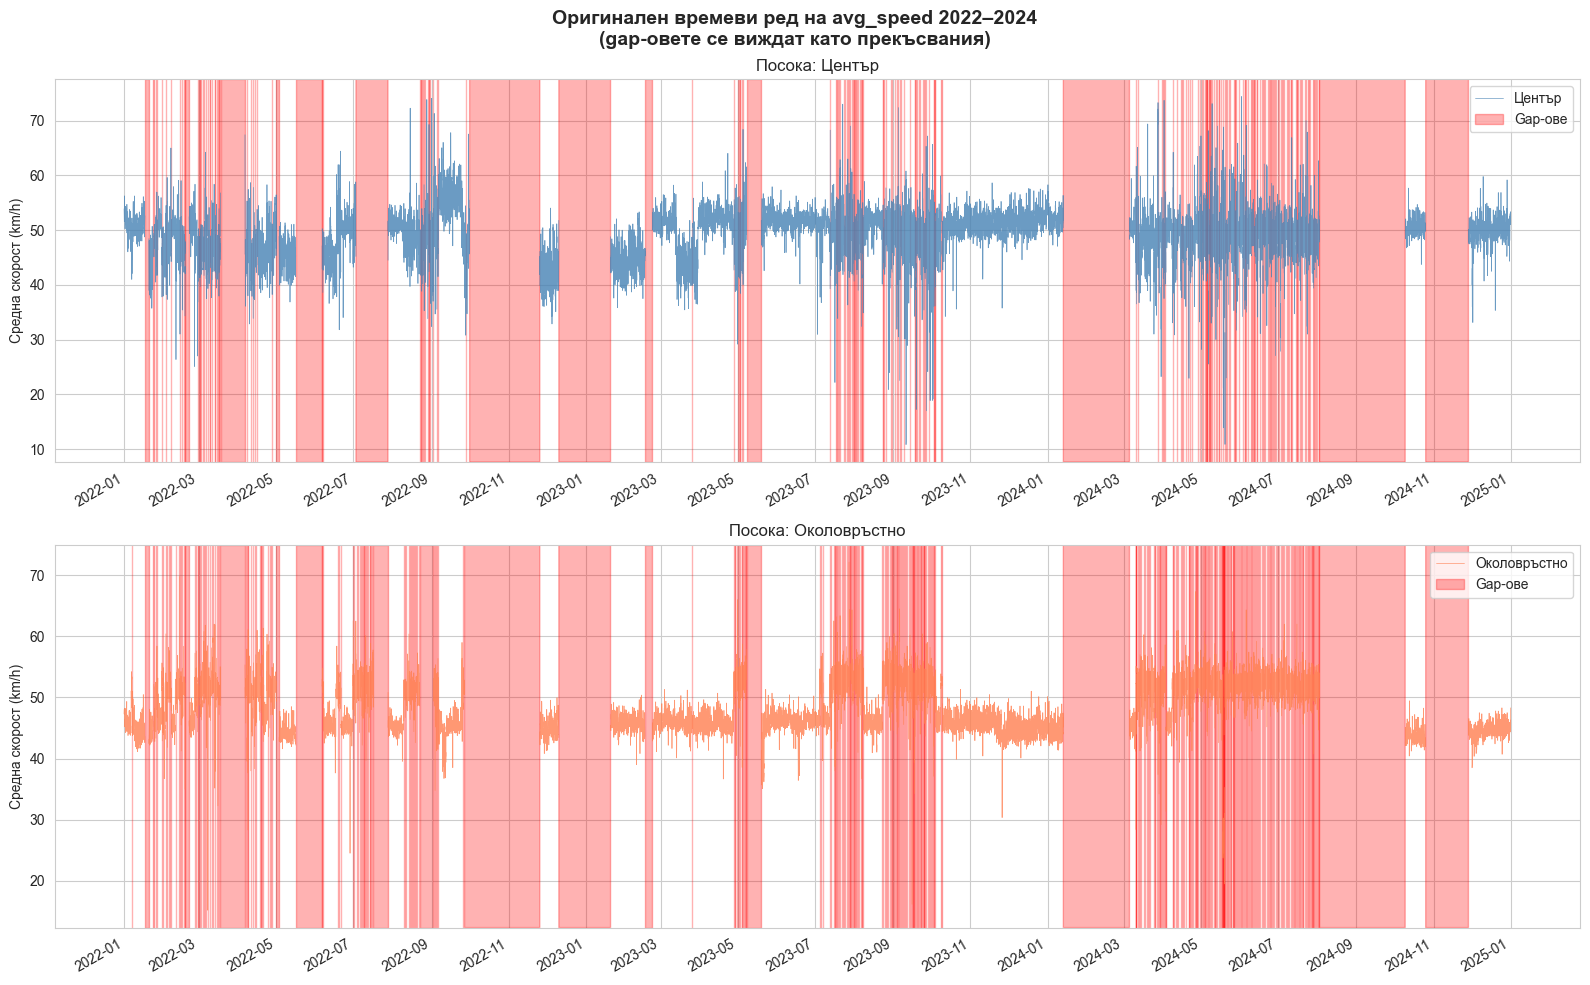


Статистика за gap-овете (avg_speed):
  Общо null часове    : 17,977
  % липсващи          : 34.2%
  Часове с данни      : 34,631


In [2]:
print("=" * 60)
print("ВИЗУАЛИЗАЦИЯ НА ОРИГИНАЛНИЯ ВРЕМЕВИ РЕД (avg_speed)")
print("=" * 60)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Оригинален времеви ред на avg_speed 2022–2024\n(gap-овете се виждат като прекъсвания)",
             fontsize=14, fontweight="bold")

for ax, direction, color in zip(axes, ["Център", "Околовръстно"],
                                 ["steelblue", "coral"]):
    sub = df[df["direction"] == direction]
    ax.plot(sub["datetime"], sub["avg_speed"],
            color=color, linewidth=0.5, alpha=0.8, label=direction)

    null_mask = sub["avg_speed"].isnull()
    if null_mask.any():
        ax.fill_between(sub["datetime"], 0, 1,
                        where=null_mask,
                        alpha=0.3, color="red",
                        transform=ax.get_xaxis_transform(),
                        label="Gap-ове")

    ax.set_title(f"Посока: {direction}")
    ax.set_ylabel("Средна скорост (km/h)")
    ax.legend(loc="upper right")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("original_speed_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nСтатистика за gap-овете (avg_speed):")
print(f"  Общо null часове    : {df['avg_speed'].isnull().sum():,}")
print(f"  % липсващи          : {df['avg_speed'].isnull().mean()*100:.1f}%")
print(f"  Часове с данни      : {df['avg_speed'].notna().sum():,}")

In [3]:
print("=" * 60)
print("ХИБРИДНА ИМПУТАЦИЯ НА avg_speed: RF + GAN")
print("=" * 60)

# Gap-структурата на avg_speed се детектира НЕЗАВИСИМО от тази на volume —
# двата сигнала могат да липсват в различни интервали.
df_copy = df.copy()

THRESHOLD_HOURS = 168  # 1 седмица — същият праг като при volume, за методологическа консистентност

gap_info = []
for direction in ["Център", "Околовръстно"]:
    sub = df_copy[df_copy["direction"] == direction].copy()
    sub = sub.reset_index(drop=True)

    in_gap    = False
    gap_start = None
    gap_idx   = []

    for i, row in sub.iterrows():
        if pd.isnull(row["avg_speed"]) and not in_gap:
            gap_start = i
            in_gap    = True
            gap_idx   = [i]
        elif pd.isnull(row["avg_speed"]) and in_gap:
            gap_idx.append(i)
        elif not pd.isnull(row["avg_speed"]) and in_gap:
            gap_info.append({
                "direction" : direction,
                "start_idx" : gap_start,
                "end_idx"   : i - 1,
                "hours"     : len(gap_idx),
                "method"    : "GAN" if len(gap_idx) > THRESHOLD_HOURS else "RF",
                "indices"   : gap_idx.copy()
            })
            in_gap = False
            gap_idx = []

    if in_gap:
        gap_info.append({
            "direction" : direction,
            "start_idx" : gap_start,
            "end_idx"   : gap_idx[-1],
            "hours"     : len(gap_idx),
            "method"    : "GAN" if len(gap_idx) > THRESHOLD_HOURS else "RF",
            "indices"   : gap_idx.copy()
        })

gap_df = pd.DataFrame([{k: v for k, v in g.items() if k != "indices"}
                        for g in gap_info])
print(f"Общо gap-ове    : {len(gap_df):,}")
print(f"Gap-ове за RF   : {(gap_df['method']=='RF').sum():,}")
print(f"Gap-ове за GAN  : {(gap_df['method']=='GAN').sum():,}")
print(f"\nРазпределение по продължителност и метод:")
print(gap_df.groupby(["method", "direction"])["hours"].agg(["count", "sum", "mean"]))

ХИБРИДНА ИМПУТАЦИЯ НА avg_speed: RF + GAN
Общо gap-ове    : 596
Gap-ове за RF   : 577
Gap-ове за GAN  : 19

Разпределение по продължителност и метод:
                     count   sum        mean
method direction                            
GAN    Околовръстно     10  7890  789.000000
       Център            9  7859  873.222222
RF     Околовръстно    359  1481    4.125348
       Център          218   747    3.426606


In [4]:
print("=" * 60)
print("ОБУЧЕНИЕ НА МОДЕЛИТЕ (avg_speed)")
print("=" * 60)

# Тренировъчни данни — само редове с реален avg_speed
train_data     = df[df["avg_speed"].notna()].copy().reset_index(drop=True)
X_train        = train_data[feature_cols].values.astype(np.float32)
y_train        = train_data["avg_speed"].values.astype(np.float32).reshape(-1, 1)
scaler         = StandardScaler()
y_train_scaled = scaler.fit_transform(y_train)

# DataLoader за GAN
X_tensor = torch.FloatTensor(X_train).to(device)
y_tensor = torch.FloatTensor(y_train_scaled).to(device)
dataset  = TensorDataset(y_tensor, X_tensor)
loader   = DataLoader(dataset, batch_size=64, shuffle=True)

# 1. Random Forest
print("Обучаване на Random Forest...")
rf = RandomForestRegressor(
    n_estimators=200, max_depth=10,
    random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train.ravel())
print(f"  RF обучен")

# 2. GAN архитектура — идентична на тази за volume, само condition_dim се обновява автоматично
class Generator(nn.Module):
    def __init__(self, noise_dim, condition_dim, hidden_dims):
        super(Generator, self).__init__()
        layers = []
        in_dim = noise_dim + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim), nn.LeakyReLU(0.2),
                nn.BatchNorm1d(h_dim), nn.Dropout(0.1)
            ])
            in_dim = h_dim
        layers.append(nn.Linear(hidden_dims[-1], 1))
        self.model = nn.Sequential(*layers)

    def forward(self, noise, condition):
        return self.model(torch.cat([noise, condition], dim=1))

class Discriminator(nn.Module):
    def __init__(self, condition_dim, hidden_dims):
        super(Discriminator, self).__init__()
        layers = []
        in_dim = 1 + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim), nn.LeakyReLU(0.2),
                nn.Dropout(0.3)
            ])
            in_dim = h_dim
        layers.extend([nn.Linear(hidden_dims[-1], 1), nn.Sigmoid()])
        self.model = nn.Sequential(*layers)

    def forward(self, x, condition):
        return self.model(torch.cat([x, condition], dim=1))

print("Обучаване на GAN...")
G         = Generator(32, len(feature_cols), [256, 128, 64]).to(device)
D         = Discriminator(len(feature_cols), [128, 64]).to(device)
opt_G     = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_D     = optim.Adam(D.parameters(), lr=0.0001, betas=(0.5, 0.999))
criterion = nn.BCELoss()

for epoch in range(400):
    for y_real, x_cond in loader:
        batch_size  = y_real.size(0)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        opt_D.zero_grad()
        d_real  = D(y_real, x_cond)
        noise   = torch.randn(batch_size, 32).to(device)
        y_fake  = G(noise, x_cond)
        d_loss  = (criterion(d_real, real_labels) +
                   criterion(D(y_fake.detach(), x_cond), fake_labels)) / 2
        d_loss.backward()
        opt_D.step()

        opt_G.zero_grad()
        noise  = torch.randn(batch_size, 32).to(device)
        y_fake = G(noise, x_cond)
        g_loss = criterion(D(y_fake, x_cond), real_labels)
        g_loss.backward()
        opt_G.step()

    if (epoch + 1) % 100 == 0:
        print(f"  Epoch {epoch+1}/400: G={g_loss.item():.4f}, D={d_loss.item():.4f}")

print(f"  GAN обучен")

# ============================================================
# ХИБРИДНА ИМПУТАЦИЯ
# ============================================================
print("\n" + "=" * 60)
print("ПРИЛАГАНЕ НА ХИБРИДНА ИМПУТАЦИЯ (avg_speed)")
print("=" * 60)

df_speed_imputed = df.copy()
rf_count  = 0
gan_count = 0

for gap in gap_info:
    direction = gap["direction"]
    indices   = gap["indices"]
    method    = gap["method"]

    dir_df   = df[df["direction"] == direction].reset_index(drop=True)
    gap_rows = dir_df.iloc[indices]
    X_gap    = gap_rows[feature_cols].values.astype(np.float32)

    if method == "RF":
        imputed_vals = rf.predict(X_gap)
        imputed_vals = np.maximum(imputed_vals, 0)
        rf_count    += len(indices)
    else:  # GAN
        G.eval()
        with torch.no_grad():
            X_tensor_gap = torch.FloatTensor(X_gap).to(device)
            samples      = []
            for _ in range(50):
                noise  = torch.randn(len(X_gap), 32).to(device)
                output = G(noise, X_tensor_gap)
                samples.append(output.cpu().numpy())
            mean_output  = np.mean(samples, axis=0)
            imputed_vals = np.maximum(
                scaler.inverse_transform(mean_output), 0
            ).flatten()
        gan_count += len(indices)

    dir_mask = df_speed_imputed["direction"] == direction
    dir_indices_global = df_speed_imputed[dir_mask].index[indices]
    df_speed_imputed.loc[dir_indices_global, "avg_speed"] = imputed_vals
    df_speed_imputed.loc[dir_indices_global, "speed_imputation_method"] = method

print(f"Попълнени с RF  : {rf_count:,} часа")
print(f"Попълнени с GAN : {gan_count:,} часа")
print(f"Оставащи null   : {df_speed_imputed['avg_speed'].isnull().sum():,}")

ОБУЧЕНИЕ НА МОДЕЛИТЕ (avg_speed)
Обучаване на Random Forest...
  RF обучен
Обучаване на GAN...
  Epoch 100/400: G=0.6909, D=0.6986
  Epoch 200/400: G=0.6950, D=0.6972
  Epoch 300/400: G=0.6942, D=0.6918
  Epoch 400/400: G=0.6972, D=0.6886
  GAN обучен

ПРИЛАГАНЕ НА ХИБРИДНА ИМПУТАЦИЯ (avg_speed)
Попълнени с RF  : 2,228 часа
Попълнени с GAN : 15,749 часа
Оставащи null   : 0


ВИЗУАЛИЗАЦИЯ НА ПОПЪЛНЕНИЯ ВРЕМЕВИ РЕД (avg_speed)


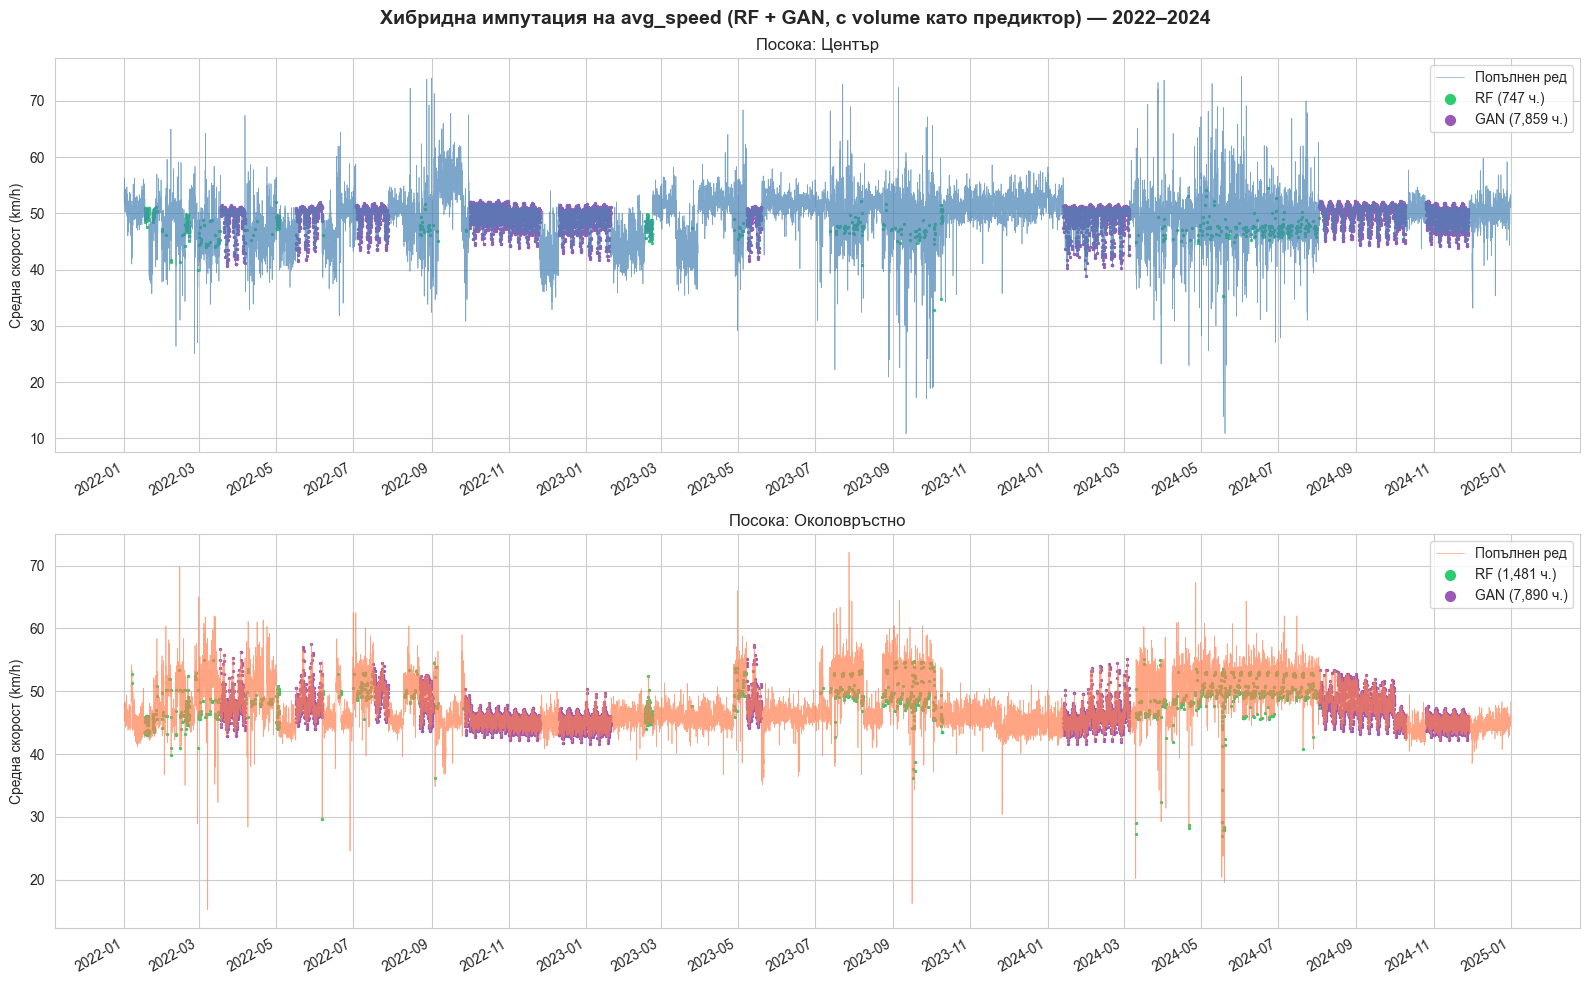

In [5]:
print("=" * 60)
print("ВИЗУАЛИЗАЦИЯ НА ПОПЪЛНЕНИЯ ВРЕМЕВИ РЕД (avg_speed)")
print("=" * 60)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Хибридна импутация на avg_speed (RF + GAN, с volume като предиктор) — 2022–2024",
             fontsize=14, fontweight="bold")

colors     = {"Център": "steelblue", "Околовръстно": "coral"}
imp_colors = {"RF": "#2ecc71", "GAN": "#9b59b6"}

for ax, direction in zip(axes, ["Център", "Околовръстно"]):
    imputed = df_speed_imputed[df_speed_imputed["direction"] == direction].copy().reset_index(drop=True)

    ax.plot(imputed["datetime"], imputed["avg_speed"],
            color=colors[direction], linewidth=0.5, alpha=0.7, label="Попълнен ред")

    rf_mask  = imputed["speed_imputation_method"] == "RF"
    gan_mask = imputed["speed_imputation_method"] == "GAN"
    ax.scatter(imputed.loc[rf_mask, "datetime"], imputed.loc[rf_mask, "avg_speed"],
               s=2, color=imp_colors["RF"], label=f"RF ({rf_mask.sum():,} ч.)")
    ax.scatter(imputed.loc[gan_mask, "datetime"], imputed.loc[gan_mask, "avg_speed"],
               s=2, color=imp_colors["GAN"], label=f"GAN ({gan_mask.sum():,} ч.)")

    ax.set_title(f"Посока: {direction}")
    ax.set_ylabel("Средна скорост (km/h)")
    ax.legend(loc="upper right", markerscale=5)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("imputed_speed_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
df_speed_imputed.to_csv("data/traffic_fully_imputed.csv", index=False)
print(f"Запазено в data/traffic_fully_imputed.csv")
print(f"Редове                     : {len(df_speed_imputed):,}")
print(f"Null avg_speed             : {df_speed_imputed['avg_speed'].isnull().sum():,}")
print(f"Импутирано с RF            : {(df_speed_imputed['speed_imputation_method']=='RF').sum():,}")
print(f"Импутирано с GAN           : {(df_speed_imputed['speed_imputation_method']=='GAN').sum():,}")
print(f"Оригинални avg_speed данни : {df_speed_imputed['speed_imputation_method'].isna().sum():,}")
print(f"\n(Забележка: volume вече е 100% попълнен от предходната тетрадка;")
print(f" колоната 'volume_is_imputed' в df маркира кои от тях са синтетични —")
print(f" полезно за анализ на верижната несигурност в главата 'Ограничения'.)")

Запазено в data/traffic_fully_imputed.csv
Редове                     : 52,608
Null avg_speed             : 0
Импутирано с RF            : 2,228
Импутирано с GAN           : 15,749
Оригинални avg_speed данни : 34,631

(Забележка: volume вече е 100% попълнен от предходната тетрадка;
 колоната 'volume_is_imputed' в df маркира кои от тях са синтетични —
 полезно за анализ на верижната несигурност в главата 'Ограничения'.)
